In [ ]:
import zipfile
import os

zip_path = '/content/cats_and_dogs_filtered.zip'
extract_path = '/content/'

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print(f"Extracted all files to: {extract_path}")
print("Contents:", os.listdir(extract_path)[:10])


Extracted all files to: /content/
Contents: ['.config', 'cats_and_dogs_filtered', 'cats_and_dogs_filtered.zip', 'linkedin_vs_interpol_split', 'sample_data']


### Step 2: Dataset Exploration


In [ ]:
import os
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import random

base_dir = '/content/cats_and_dogs_filtered'
train_dir = os.path.join(base_dir, 'train')
validation_dir = os.path.join(base_dir, 'validation')

train_cats_dir = os.path.join(train_dir, 'cats')
train_dogs_dir = os.path.join(train_dir, 'dogs')

validation_cats_dir = os.path.join(validation_dir, 'cats')
validation_dogs_dir = os.path.join(validation_dir, 'dogs')

print('total training cat images:', len(os.listdir(train_cats_dir)))
print('total training dog images:', len(os.listdir(train_dogs_dir)))
print('total validation cat images:', len(os.listdir(validation_cats_dir)))
print('total validation dog images:', len(os.listdir(validation_dogs_dir)))

total training cat images: 1000
total training dog images: 1000
total validation cat images: 500
total validation dog images: 500



Sample Training Cat Images:


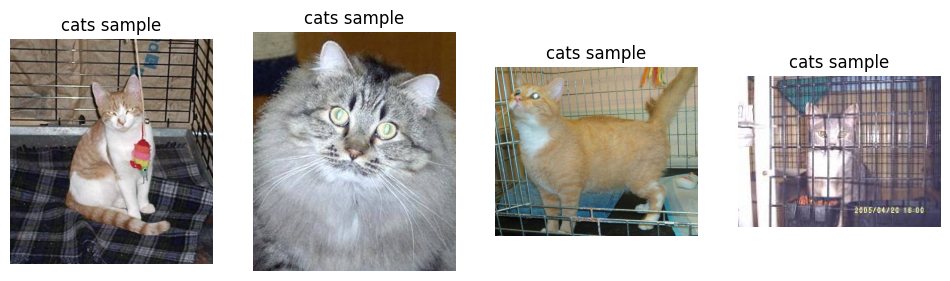


Sample Training Dog Images:


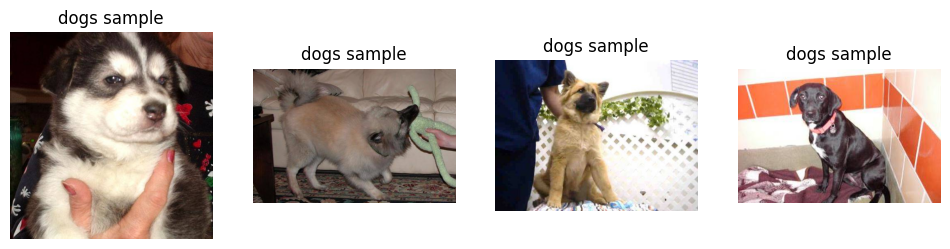

In [ ]:
def show_sample_images(image_dir, num_images=4):
    plt.figure(figsize=(12, 4))
    image_files = os.listdir(image_dir)
    sample_files = random.sample(image_files, num_images)

    for i, file_name in enumerate(sample_files):
        img_path = os.path.join(image_dir, file_name)
        img = mpimg.imread(img_path)
        plt.subplot(1, num_images, i + 1)
        plt.imshow(img)
        plt.axis('off')
        plt.title(f"{os.path.basename(image_dir)} sample")
    plt.show()

print("\nSample Training Cat Images:")
show_sample_images(train_cats_dir)

print("\nSample Training Dog Images:")
show_sample_images(train_dogs_dir)

/tmp/ipykernel_940/3711238721.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=classes, y=counts, palette='viridis')


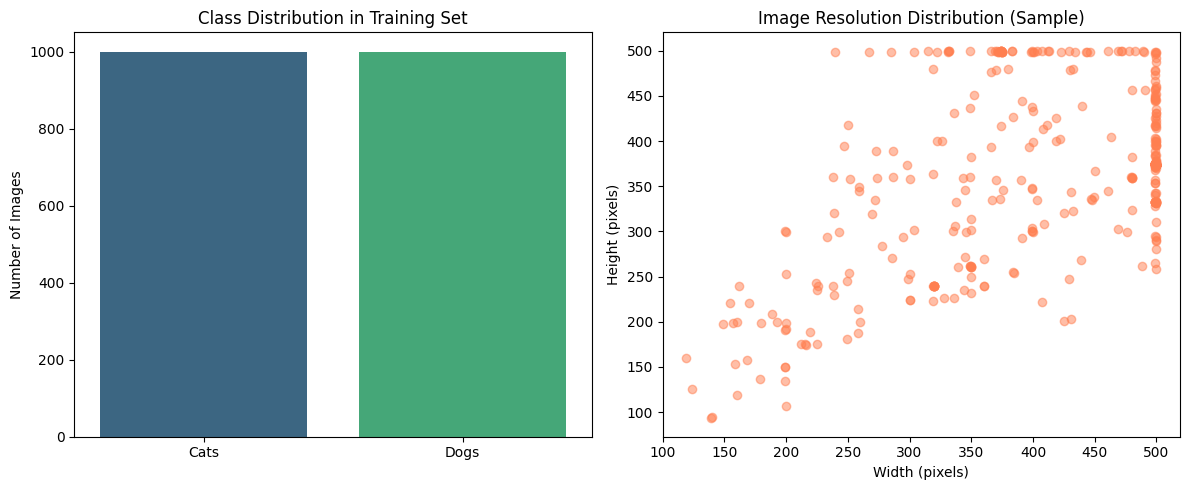

Average Width: 409.34px, Average Height: 360.57px


In [ ]:
import seaborn as sns
from PIL import Image
import numpy as np

classes = ['Cats', 'Dogs']
counts = [len(os.listdir(train_cats_dir)), len(os.listdir(train_dogs_dir))]

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.barplot(x=classes, y=counts, palette='viridis')
plt.title('Class Distribution in Training Set')
plt.ylabel('Number of Images')

sample_size = 200
shapes = []

for img_name in random.sample(os.listdir(train_cats_dir), sample_size):
    with Image.open(os.path.join(train_cats_dir, img_name)) as img:
        shapes.append(img.size)

for img_name in random.sample(os.listdir(train_dogs_dir), sample_size):
    with Image.open(os.path.join(train_dogs_dir, img_name)) as img:
        shapes.append(img.size)

widths, heights = zip(*shapes)

plt.subplot(1, 2, 2)
plt.scatter(widths, heights, alpha=0.5, color='coral')
plt.title('Image Resolution Distribution (Sample)')
plt.xlabel('Width (pixels)')
plt.ylabel('Height (pixels)')

plt.tight_layout()
plt.show()

print(f"Average Width: {np.mean(widths):.2f}px, Average Height: {np.mean(heights):.2f}px")

In [ ]:
import os
import shutil
from sklearn.model_selection import train_test_split

orig_train_cats_dir = '/content/cats_and_dogs_filtered/train/cats'
orig_train_dogs_dir = '/content/cats_and_dogs_filtered/train/dogs'

split_base_dir = '/content/cats_and_dogs_split'

if os.path.exists(split_base_dir):
    shutil.rmtree(split_base_dir)

split_train_dir = os.path.join(split_base_dir, 'train')
split_test_dir = os.path.join(split_base_dir, 'test')

for category in ['cats', 'dogs']:
    os.makedirs(os.path.join(split_train_dir, category), exist_ok=True)
    os.makedirs(os.path.join(split_test_dir, category), exist_ok=True)

for category, orig_dir in zip(['cats', 'dogs'], [orig_train_cats_dir, orig_train_dogs_dir]):
    files = os.listdir(orig_dir)

    train_files, test_files = train_test_split(files, test_size=0.2, random_state=42)

    for f in train_files:
        shutil.copy(os.path.join(orig_dir, f), os.path.join(split_train_dir, category, f))
    for f in test_files:
        shutil.copy(os.path.join(orig_dir, f), os.path.join(split_test_dir, category, f))

print("Data splitting complete!")
print(f"New Training Cats: {len(os.listdir(os.path.join(split_train_dir, 'cats')))}")
print(f"New Training Dogs: {len(os.listdir(os.path.join(split_train_dir, 'dogs')))}")
print(f"New Test Cats: {len(os.listdir(os.path.join(split_test_dir, 'cats')))}")
print(f"New Test Dogs: {len(os.listdir(os.path.join(split_test_dir, 'dogs')))}")

train_dir = split_train_dir
train_cats_dir = os.path.join(split_train_dir, 'cats')
train_dogs_dir = os.path.join(split_train_dir, 'dogs')

Data splitting complete!
New Training Cats: 800
New Training Dogs: 800
New Test Cats: 200
New Test Dogs: 200


## Step 3 : Build CNN Model

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models

model = models.Sequential([
    layers.Input(shape=(150, 150, 3)),

    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D(2, 2),

    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D(2, 2),

    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D(2, 2),

    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D(2, 2),

    layers.Flatten(),
    layers.Dropout(0.5),

    layers.Dense(512, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])

model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
              loss='binary_crossentropy',
              metrics=['accuracy'])

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_4 (Conv2D)               │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 34, 34, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 15, 15, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 512)            │     3,211,776 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           513 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,453,121 (13.17 MB)

 Trainable params: 3,453,121 (13.17 MB)

 Non-trainable params: 0 (0.00 B)

To calculate the number of parameters in a Convolutional Neural Network (CNN) mathematically, we look at each layer type individually. Let's break down the calculations layer by layer based on your model architecture:

# 1. 2D Convolutional Layers (Conv2D)

A convolutional layer's parameters consist of the weights of the filters plus the biases for each filter.

$\text{Parameters} = (\text{Filter Width} \times \text{Filter Height} \times \text{Input Channels} + 1) \times \text{Number of Filters}$

Where the $+1$ represents the bias term for each filter.

## First Conv2D Layer:

Input Channels: 3 (RGB image)

Filter Size: $3 \times 3$

Filters: 32

Calculation: $(3 \times 3 \times 3 + 1) \times 32 = (27 + 1) \times 32 = 896$ parameters.

## Second Conv2D Layer:

Input Channels: 32 (output from the previous layer)

Filter Size: $3 \times 3$

Filters: 64

Calculation: $(3 \times 3 \times 32 + 1) \times 64 = (288 + 1) \times 64 = 18,496$ parameters.

## Third Conv2D Layer:

Input Channels: 64

Filter Size: $3 \times 3$

Filters: 128

Calculation: $(3 \times 3 \times 64 + 1) \times 128 = (576 + 1) \times 128 = 73,856$ parameters.

## Fourth Conv2D Layer:

Input Channels: 128

Filter Size: $3 \times 3$

Filters: 128

Calculation: $(3 \times 3 \times 128 + 1) \times 128 = (1152 + 1) \times 128 = 147,584$ parameters.

# 2. Pooling and Flatten Layers (MaxPooling2D & Flatten)

## MaxPooling2D Layers:

Pooling layers simply partition the feature map and extract maximum values.

They perform no mathematical weight multiplications. Therefore, they have 0 parameters.

## Flatten Layer:

This layer simply reshapes a multi-dimensional tensor into a 1D vector.

It has 0 parameters.

To calculate the input size for the upcoming Dense layer, let's track the spatial dimensions (Width $\times$ Height $\times$Channels) starting from $150 \times 150 \times 3$:

Conv2D (32 filters, no padding): Shrinks spatial dimensions by 2 pixels
$\rightarrow 148 \times 148 \times 32$

MaxPool (pool size 2): Divides spatial dimensions by 2 $\rightarrow 74 \times 74 \times 32$

Conv2D (64 filters): Shrinks spatial dimensions $\rightarrow 72 \times 72 \times 64$

MaxPool (pool size 2): Divides spatial dimensions $\rightarrow 36 \times 36 \times 64$

Conv2D (128 filters): Shrinks spatial dimensions $\rightarrow 34 \times 34 \times 128$

MaxPool (pool size 2): Divides spatial dimensions $\rightarrow 17 \times 17 \times 128$

Conv2D (128 filters): Shrinks spatial dimensions $\rightarrow 15 \times 15 \times 128$

MaxPool (pool size 2): Divides spatial dimensions (rounding down in Keras default behavior) $\rightarrow 7 \times 7 \times 128$

Flatten Layer: Flattens the $7 \times 7 \times 128$ output into a 1D vector of size 6,272 ($7 \times 7 \times 128 = 6272$).

# 3. Fully Connected Layers (Dense)

A dense layer connects every input unit to every output unit.

Each connection has a weight, and each output unit has a bias.

$\text{Parameters} = (\text{Input Units} + 1) \times \text{Output Units}$

## First Dense Layer:

Input Units: 6,272 (from the Flatten layer)

Output Units: 512

Calculation: $(6272 + 1) \times 512 = 3,211,776$ parameters.

## Output Dense Layer:

Input Units: 512

Output Units: 1

Calculation: $(512 + 1) \times 1 = 513$ parameters.

Total Summary

Adding up the parameters from all layers:

$$ \begin{align*} \text{Total Parameters} &= 896 \quad (\text{Conv1}) \\ &\quad + 18,496 \quad (\text{Conv2}) \\ &\quad + 73,856 \quad (\text{Conv3}) \\ &\quad + 147,584 \quad (\text{Conv4}) \\ &\quad + 3,211,776 \quad (\text{Dense1}) \\ &\quad + 513 \quad (\text{Output}) \\ &= \mathbf{3,453,121} \text{ parameters} \end{align*} $$

This perfectly matches Keras's model.summary() output!

### Step 4: Model Training

In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

train_datagen = ImageDataGenerator(
    rescale=1./255,
    shear_range=0.1,
    fill_mode='nearest'
)

test_datagen = ImageDataGenerator(rescale=1./255)

train_generator = train_datagen.flow_from_directory(
    split_train_dir,
    target_size=(150, 150),
    batch_size=32,
    class_mode='binary'
)

validation_generator = test_datagen.flow_from_directory(
    split_test_dir,
    target_size=(150, 150),
    batch_size=32,
    class_mode='binary'
)

print("\nStarting training...")
history = model.fit(
    train_generator,
    epochs=10,
    validation_data=validation_generator
)

Found 1600 images belonging to 2 classes.
Found 400 images belonging to 2 classes.

Starting training...
Epoch 1/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 110s 2s/step - accuracy: 0.6575 - loss: 0.6238 - val_accuracy: 0.6475 - val_loss: 0.6486
Epoch 2/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 106s 2s/step - accuracy: 0.6938 - loss: 0.5913 - val_accuracy: 0.7000 - val_loss: 0.6193
Epoch 3/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 122s 2s/step - accuracy: 0.6906 - loss: 0.5785 - val_accuracy: 0.6050 - val_loss: 0.6554
Epoch 4/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 105s 2s/step - accuracy: 0.7131 - loss: 0.5555 - val_accuracy: 0.6375 - val_loss: 0.6358
Epoch 5/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 107s 2s/step - accuracy: 0.7369 - loss: 0.5126 - val_accuracy: 0.6550 - val_loss: 0.6605
Epoch 6/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 110s 2s/step - accuracy: 0.7525 - loss: 0.4891 - val_accuracy: 0.6950 - val_loss: 0.6387
Epoch 7/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 105s 2s/step - accuracy: 0.7862 - loss: 0.4567 - val_accuracy: 0.6750 - val_loss: 0.6381
Epoch 

Found 400 images belonging to 2 classes.
4/4 ━━━━━━━━━━━━━━━━━━━━ 14s 3s/step

--- Evaluation Metrics on Test Set ---
Accuracy:  0.6875
Precision: 0.6569
Recall:    0.7850
F1-Score:  0.7153


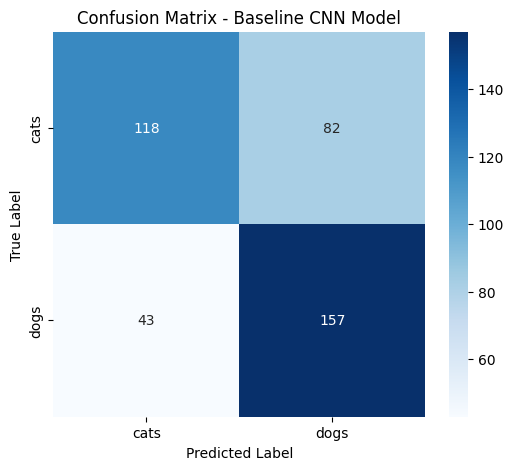

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

validation_generator = test_datagen.flow_from_directory(
    split_test_dir,
    target_size=(150, 150),
    batch_size=100,
    class_mode='binary',
    shuffle=False
)

validation_generator.reset()

y_pred_prob = model.predict(validation_generator, verbose=1)
y_pred = (y_pred_prob > 0.5).astype(int).flatten()

y_true = validation_generator.classes

class_labels = list(validation_generator.class_indices.keys())

accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred)
recall = recall_score(y_true, y_pred)
f1 = f1_score(y_true, y_pred)

print("\n--- Evaluation Metrics on Test Set ---")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-Score:  {f1:.4f}")

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_labels, yticklabels=class_labels)
plt.title('Confusion Matrix - Baseline CNN Model')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.show()

=== Improvement: Transfer Learning with MobileNetV2 + Data Augmentation ===
Found 1600 images belonging to 2 classes.
Found 400 images belonging to 2 classes.
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

--- Phase 1: Training top layers (Feature Extraction) ---
Epoch 1/5
50/50 ━━━━━━━━━━━━━━━━━━━━ 80s 2s/step - accuracy: 0.8519 - loss: 0.3556 - val_accuracy: 0.9725 - val_loss: 0.1216
Epoch 2/5
50/50 ━━━━━━━━━━━━━━━━━━━━ 65s 1s/step - accuracy: 0.9456 - loss: 0.1547 - val_accuracy: 0.9825 - val_loss: 0.0787
Epoch 3/5
50/50 ━━━━━━━━━━━━━━━━━━━━ 65s 1s/step - accuracy: 0.9525 - loss: 0.1216 - val_accuracy: 0.9875 - val_loss: 0.0625
Epoch 4/5
50/50 ━━━━━━━━━━━━━━━━━━━━ 64s 1s/step - accuracy: 0.9656 - loss: 0.1017 - val_accuracy: 0.9925 - val_loss: 0.0533
Epoch 5/5
50/50 ━━━━━━━━━━━━━━━━━━━━ 65s 1s/step - accuracy: 0.9638 - loss: 0.1004 - val_accuracy: 0.9900 - val_loss: 0.0496

--- Phase 2: Fine-tuning top 30 layers of base model ---
Epoch 1/5
50/50 ━━━━━━━━━━━━━━━━━━━━ 95s 2s/step -

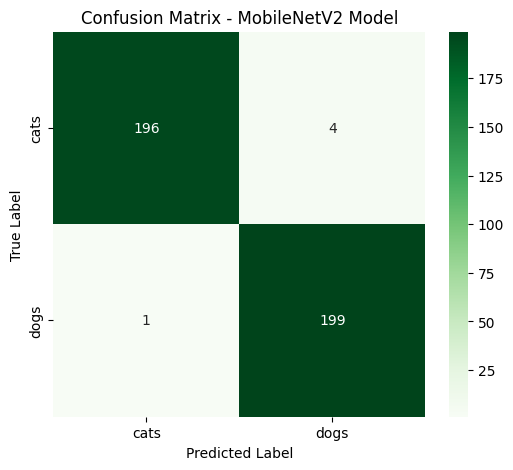

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.metrics import accuracy_score, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

print("=== Improvement: Transfer Learning with MobileNetV2 + Data Augmentation ===")

train_datagen_tl = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True
)

test_datagen_tl = ImageDataGenerator(preprocessing_function=preprocess_input)

tl_size = (160, 160)

train_generator_tl = train_datagen_tl.flow_from_directory(
    split_train_dir,
    target_size=tl_size,
    batch_size=32,
    class_mode='binary'
)

validation_generator_tl = test_datagen_tl.flow_from_directory(
    split_test_dir,
    target_size=tl_size,
    batch_size=32,
    class_mode='binary',
    shuffle=False
)

base_model = tf.keras.applications.MobileNetV2(
    input_shape=tl_size + (3,),
    include_top=False,
    weights='imagenet'
)

base_model.trainable = False

model_tl = models.Sequential([
    layers.Input(shape=tl_size + (3,)),
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(1, activation='sigmoid')
])

model_tl.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
              loss='binary_crossentropy',
              metrics=['accuracy'])

print("\n--- Phase 1: Training top layers (Feature Extraction) ---")
history_tl = model_tl.fit(
    train_generator_tl,
    epochs=5,
    validation_data=validation_generator_tl
)

print("\n--- Phase 2: Fine-tuning top 30 layers of base model ---")
base_model.trainable = True
for layer in base_model.layers[:-30]:
    layer.trainable = False

model_tl.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
              loss='binary_crossentropy',
              metrics=['accuracy'])

history_ft = model_tl.fit(
    train_generator_tl,
    epochs=5,
    validation_data=validation_generator_tl
)

print("\n--- Evaluating Final Model ---")
validation_generator_tl.reset()
y_pred_prob_tl = model_tl.predict(validation_generator_tl)
y_pred_tl = (y_pred_prob_tl > 0.5).astype(int).flatten()
y_true_tl = validation_generator_tl.classes

acc_tl = accuracy_score(y_true_tl, y_pred_tl)
print(f"\nFinal Transfer Learning Model Accuracy: {acc_tl:.4f}")

cm_tl = confusion_matrix(y_true_tl, y_pred_tl)
class_labels = list(validation_generator_tl.class_indices.keys())

plt.figure(figsize=(6, 5))
sns.heatmap(cm_tl, annot=True, fmt='d', cmap='Greens', xticklabels=class_labels, yticklabels=class_labels)
plt.title('Confusion Matrix - MobileNetV2 Model')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.show()


---

# Linkedin or Interpol AI

In [ ]:
import os
!pip install -q datasets kagglehub

import kagglehub
import random

print("Downloading CelebA face dataset from Kaggle (Proxy for Profile Pictures)...")
faces_path = kagglehub.dataset_download("jessicali9530/celeba-dataset")

linkedin_images = []
for root, dirs, files in os.walk(faces_path):
    for file in files:
        if file.lower().endswith(('.png', '.jpg', '.jpeg')):
            linkedin_images.append(os.path.join(root, file))

print(f"Found {len(linkedin_images)} face images.")

print("\nDownloading Kaggle Interpol dataset...")
kaggle_path = kagglehub.dataset_download("henriquelimag/most-wanted-criminals-fbi-interpol-br-police")

interpol_images = []
for root, dirs, files in os.walk(kaggle_path):
    for file in files:
        if file.lower().endswith(('.png', '.jpg', '.jpeg')):
            interpol_images.append(os.path.join(root, file))

print(f"Found {len(interpol_images)} Interpol/Criminal images.")

max_balanced_count = min(len(linkedin_images), len(interpol_images))
print(f"\nBalancing datasets to {max_balanced_count} images each...")

if max_balanced_count > 0:
    linkedin_sample = random.sample(linkedin_images, max_balanced_count)
    interpol_sample = random.sample(interpol_images, max_balanced_count)
    print(f"Final LinkedIn/Real Face Sample Size: {len(linkedin_sample)}")
    print(f"Final Interpol Sample Size: {len(interpol_sample)}")
else:
    print("One of the datasets returned 0 images. Please review dataset availability and schema.")

Using Colab cache for faster access to the 'celeba-dataset' dataset.
Found 202599 face images.



100%|██████████| 397M/397M [00:07<00:00, 57.0MB/s]

Extracting files...


Found 9584 Interpol/Criminal images.

Balancing datasets to 9584 images each...
Final LinkedIn/Real Face Sample Size: 9584
Final Interpol Sample Size: 9584


### Prepare Directories and Split Data

In [ ]:
import shutil
from sklearn.model_selection import train_test_split

base_new_dir = '/content/linkedin_vs_interpol_split'
if os.path.exists(base_new_dir):
    shutil.rmtree(base_new_dir)

train_dir_li = os.path.join(base_new_dir, 'train')
test_dir_li = os.path.join(base_new_dir, 'test')

os.makedirs(os.path.join(train_dir_li, 'linkedin'), exist_ok=True)
os.makedirs(os.path.join(train_dir_li, 'interpol'), exist_ok=True)
os.makedirs(os.path.join(test_dir_li, 'linkedin'), exist_ok=True)
os.makedirs(os.path.join(test_dir_li, 'interpol'), exist_ok=True)

li_train, li_test = train_test_split(linkedin_sample, test_size=0.2, random_state=42)
int_train, int_test = train_test_split(interpol_sample, test_size=0.2, random_state=42)

print("Copying images into training and testing directories (this might take a moment)...")

for i, f in enumerate(li_train):
    shutil.copy(f, os.path.join(train_dir_li, 'linkedin', f"li_train_{i}.jpg"))
for i, f in enumerate(li_test):
    shutil.copy(f, os.path.join(test_dir_li, 'linkedin', f"li_test_{i}.jpg"))

for i, f in enumerate(int_train):
    shutil.copy(f, os.path.join(train_dir_li, 'interpol', f"int_train_{i}.jpg"))
for i, f in enumerate(int_test):
    shutil.copy(f, os.path.join(test_dir_li, 'interpol', f"int_test_{i}.jpg"))

print("Data split and copied successfully!")
print(f"Training images: {len(li_train) + len(int_train)}")
print(f"Testing images: {len(li_test) + len(int_test)}")

Copying images into training and testing directories (this might take a moment)...
Data split and copied successfully!
Training images: 15334
Testing images: 3834


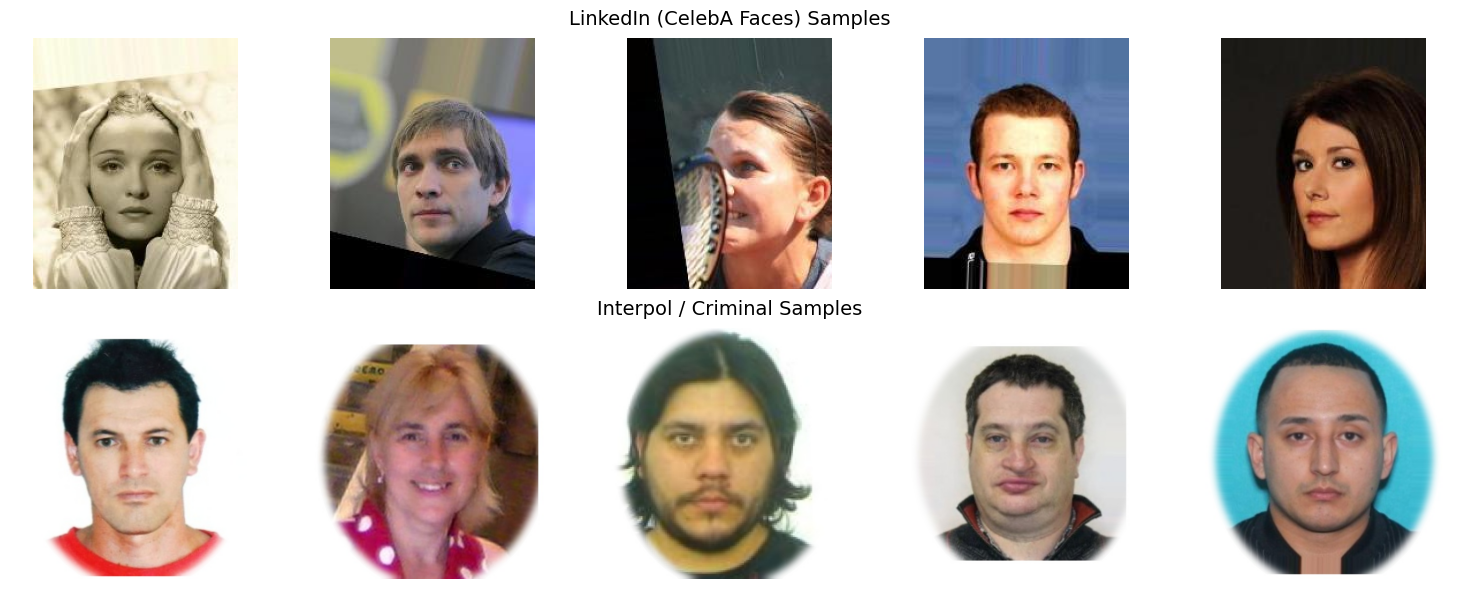

In [ ]:
import random
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

num_samples = 5
random_linkedin = random.sample(linkedin_sample, num_samples)
random_interpol = random.sample(interpol_sample, num_samples)

fig, axes = plt.subplots(2, num_samples, figsize=(15, 6))

for i, img_path in enumerate(random_linkedin):
    img = mpimg.imread(img_path)
    axes[0, i].imshow(img)
    axes[0, i].axis('off')
    if i == 2:
        axes[0, i].set_title("LinkedIn (CelebA Faces) Samples", fontsize=14, pad=10)

for i, img_path in enumerate(random_interpol):
    img = mpimg.imread(img_path)
    axes[1, i].imshow(img)
    axes[1, i].axis('off')
    if i == 2:
        axes[1, i].set_title("Interpol / Criminal Samples", fontsize=14, pad=10)

plt.tight_layout()
plt.show()

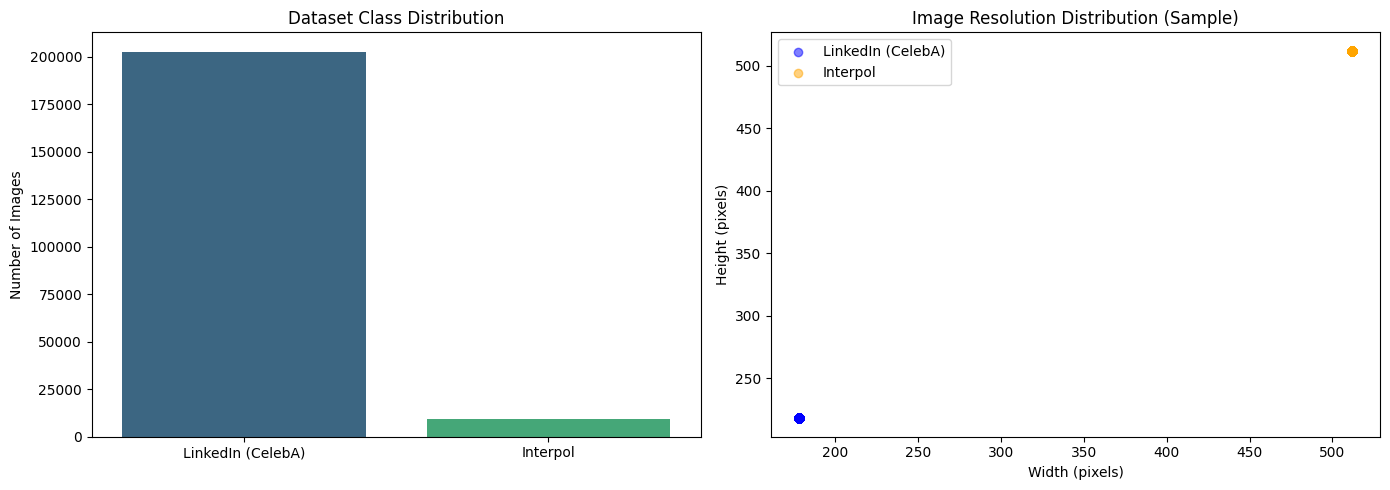

LinkedIn - Average Width: 178.00px, Average Height: 218.00px
Interpol - Average Width: 512.00px, Average Height: 512.00px


In [ ]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

classes = ['LinkedIn (CelebA)', 'Interpol']
counts = [len(linkedin_images), len(interpol_images)]

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
sns.barplot(x=classes, y=counts, hue=classes, palette='viridis', legend=False)
plt.title('Dataset Class Distribution')
plt.ylabel('Number of Images')

sample_size = 200
shapes_li = []
shapes_int = []

for img_path in random.sample(linkedin_images, min(sample_size, len(linkedin_images))):
    try:
        with Image.open(img_path) as img:
            shapes_li.append(img.size)
    except Exception:
        pass

for img_path in random.sample(interpol_images, min(sample_size, len(interpol_images))):
    try:
        with Image.open(img_path) as img:
            shapes_int.append(img.size)
    except Exception:
        pass

widths_li, heights_li = zip(*shapes_li) if shapes_li else ([], [])
widths_int, heights_int = zip(*shapes_int) if shapes_int else ([], [])

plt.subplot(1, 2, 2)
plt.scatter(widths_li, heights_li, alpha=0.5, color='blue', label='LinkedIn (CelebA)')
plt.scatter(widths_int, heights_int, alpha=0.5, color='orange', label='Interpol')
plt.title('Image Resolution Distribution (Sample)')
plt.xlabel('Width (pixels)')
plt.ylabel('Height (pixels)')
plt.legend()

plt.tight_layout()
plt.show()

if widths_li and heights_li:
    print(f"LinkedIn - Average Width: {np.mean(widths_li):.2f}px, Average Height: {np.mean(heights_li):.2f}px")
if widths_int and heights_int:
    print(f"Interpol - Average Width: {np.mean(widths_int):.2f}px, Average Height: {np.mean(heights_int):.2f}px")


Resizing Interpol images in the balanced split directories to 178x218...
Resizing complete!



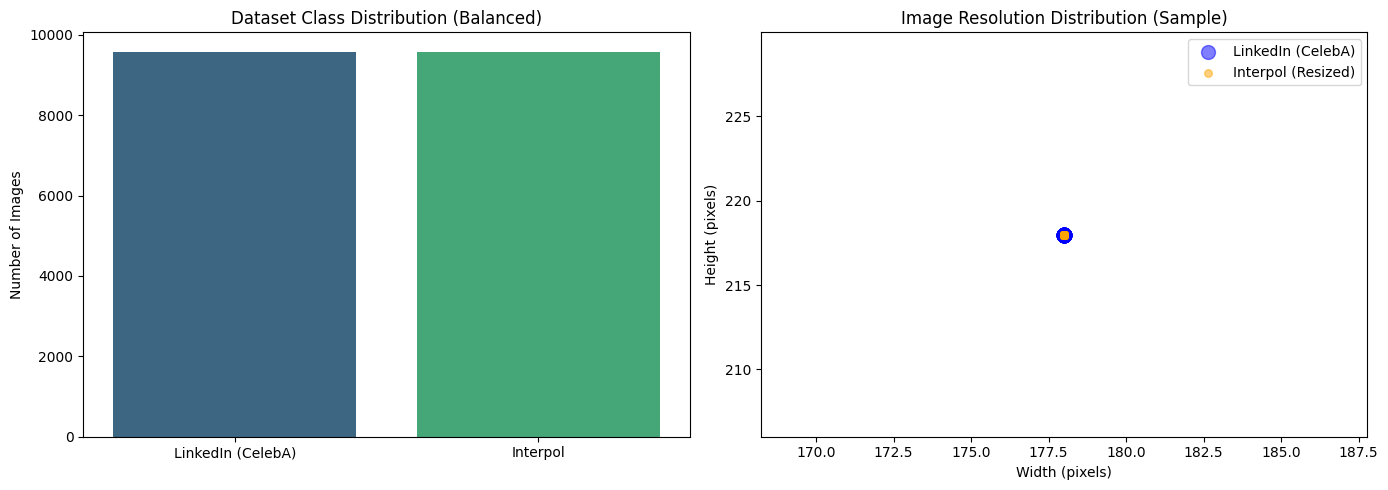

LinkedIn - Average Width: 178.00px, Average Height: 218.00px
Interpol - Average Width: 178.00px, Average Height: 218.00px


In [ ]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

classes = ['LinkedIn (CelebA)', 'Interpol']
counts = [len(linkedin_sample), len(interpol_sample)]

print("Resizing Interpol images in the balanced split directories to 178x218...")
interpol_train_dir = os.path.join(train_dir_li, 'interpol')
interpol_test_dir = os.path.join(test_dir_li, 'interpol')

for d in [interpol_train_dir, interpol_test_dir]:
    for f in os.listdir(d):
        filepath = os.path.join(d, f)
        try:
            with Image.open(filepath) as img:
                if img.size != (178, 218):
                    img = img.resize((178, 218))
                    img.save(filepath)
        except Exception:
            pass
print("Resizing complete!\n")

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
sns.barplot(x=classes, y=counts, hue=classes, palette='viridis', legend=False)
plt.title('Dataset Class Distribution (Balanced)')
plt.ylabel('Number of Images')

linkedin_train_dir = os.path.join(train_dir_li, 'linkedin')
li_files = [os.path.join(linkedin_train_dir, f) for f in os.listdir(linkedin_train_dir)]
int_files = [os.path.join(interpol_train_dir, f) for f in os.listdir(interpol_train_dir)]

sample_size = 200
shapes_li = []
shapes_int = []

for img_path in random.sample(li_files, min(sample_size, len(li_files))):
    try:
        with Image.open(img_path) as img:
            shapes_li.append(img.size)
    except Exception:
        pass

for img_path in random.sample(int_files, min(sample_size, len(int_files))):
    try:
        with Image.open(img_path) as img:
            shapes_int.append(img.size)
    except Exception:
        pass

widths_li, heights_li = zip(*shapes_li) if shapes_li else ([], [])
widths_int, heights_int = zip(*shapes_int) if shapes_int else ([], [])

plt.subplot(1, 2, 2)
plt.scatter(widths_li, heights_li, alpha=0.5, color='blue', label='LinkedIn (CelebA)', s=100)
plt.scatter(widths_int, heights_int, alpha=0.5, color='orange', label='Interpol (Resized)', s=30)
plt.title('Image Resolution Distribution (Sample)')
plt.xlabel('Width (pixels)')
plt.ylabel('Height (pixels)')
plt.legend()

plt.tight_layout()
plt.show()

if widths_li and heights_li:
    print(f"LinkedIn - Average Width: {np.mean(widths_li):.2f}px, Average Height: {np.mean(heights_li):.2f}px")
if widths_int and heights_int:
    print(f"Interpol - Average Width: {np.mean(widths_int):.2f}px, Average Height: {np.mean(heights_int):.2f}px")


### Build and Train the Baseline CNN

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing.image import ImageDataGenerator

model_faces = models.Sequential([
    layers.Input(shape=(150, 150, 3)),
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D(2, 2),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D(2, 2),
    layers.Flatten(),
    layers.Dense(512, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])

model_faces.compile(optimizer='adam',
              loss='binary_crossentropy',
              metrics=['accuracy'])

train_datagen_faces = ImageDataGenerator(rescale=1./255)
test_datagen_faces = ImageDataGenerator(rescale=1./255)

train_gen_faces = train_datagen_faces.flow_from_directory(
    train_dir_li,
    target_size=(150, 150),
    batch_size=100,
    class_mode='binary'
)

test_gen_faces = test_datagen_faces.flow_from_directory(
    test_dir_li,
    target_size=(150, 150),
    batch_size=100,
    class_mode='binary',
    shuffle=False
)

print("\nStarting training ...")
history_faces = model_faces.fit(
    train_gen_faces,
    epochs=1,
    validation_data=test_gen_faces
)

Found 15334 images belonging to 2 classes.
Found 3834 images belonging to 2 classes.

Starting training ...
154/154 ━━━━━━━━━━━━━━━━━━━━ 771s 5s/step - accuracy: 0.9719 - loss: 0.2914 - val_accuracy: 0.9990 - val_loss: 0.0035


### Evaluate on Test Set

39/39 ━━━━━━━━━━━━━━━━━━━━ 50s 1s/step

--- Evaluation Metrics on LinkedIn vs Interpol Test Set ---
Accuracy:  0.9990
Precision: 1.0000
Recall:    0.9979
F1-Score:  0.9990


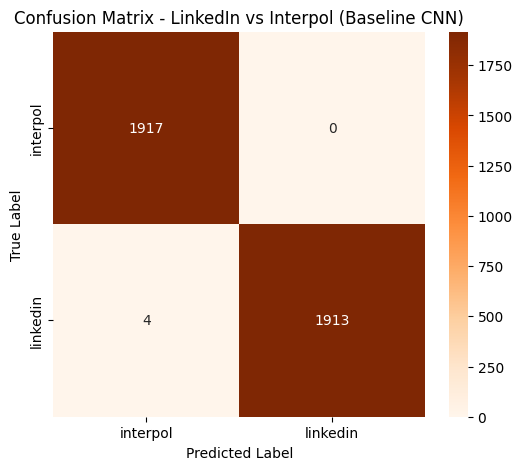

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

test_gen_faces.reset()

y_pred_prob_faces = model_faces.predict(test_gen_faces, verbose=1)
y_pred_faces = (y_pred_prob_faces > 0.5).astype(int).flatten()

y_true_faces = test_gen_faces.classes
class_labels_faces = list(test_gen_faces.class_indices.keys())

acc_faces = accuracy_score(y_true_faces, y_pred_faces)
prec_faces = precision_score(y_true_faces, y_pred_faces)
rec_faces = recall_score(y_true_faces, y_pred_faces)
f1_faces = f1_score(y_true_faces, y_pred_faces)

print("\n--- Evaluation Metrics on LinkedIn vs Interpol Test Set ---")
print(f"Accuracy:  {acc_faces:.4f}")
print(f"Precision: {prec_faces:.4f}")
print(f"Recall:    {rec_faces:.4f}")
print(f"F1-Score:  {f1_faces:.4f}")

cm_faces = confusion_matrix(y_true_faces, y_pred_faces)

plt.figure(figsize=(6, 5))
sns.heatmap(cm_faces, annot=True, fmt='d', cmap='Oranges', xticklabels=class_labels_faces, yticklabels=class_labels_faces)
plt.title('Confusion Matrix - LinkedIn vs Interpol (Baseline CNN)')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.show()

### Remove Biases: Apply Circular Mask to All Images
We noticed the Interpol dataset uses oval frames, giving the model an unfair hint. We will apply a perfect circle mask to **both** datasets so the model is forced to look at the facial features rather than the background.

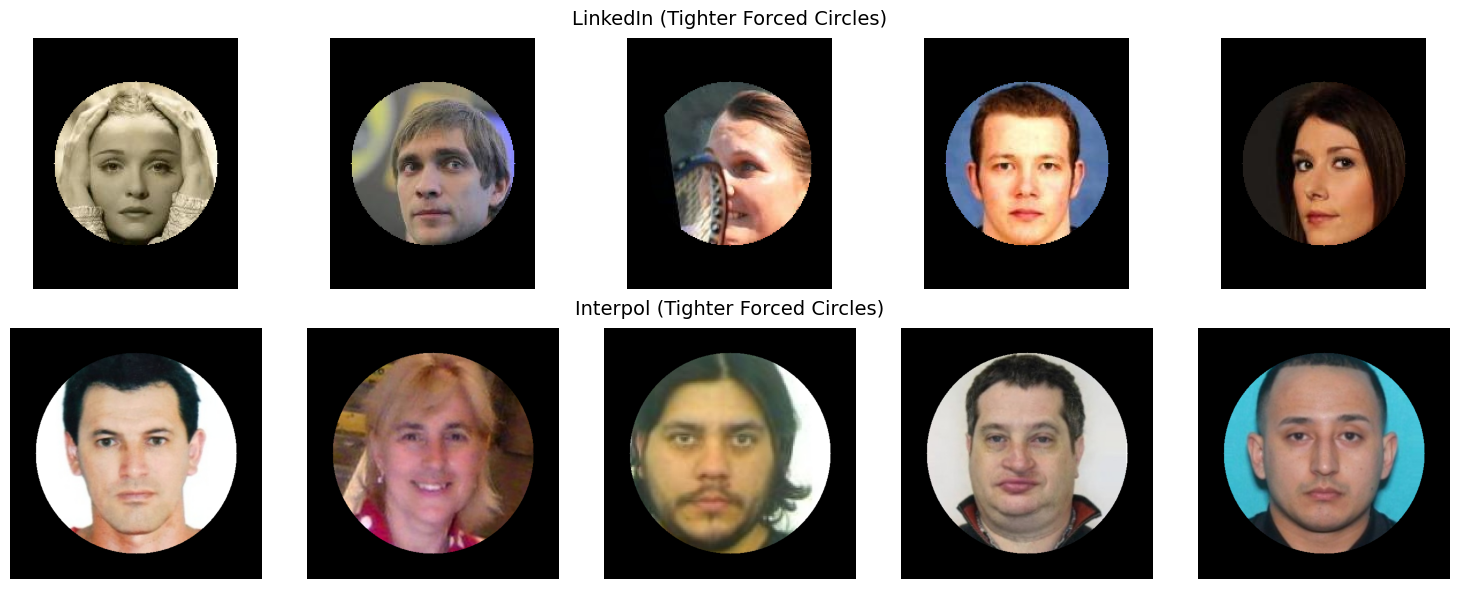

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

def apply_circle_mask(img_array):
    h, w = img_array.shape[:2]
    center = (w // 2, h // 2)

    radius = int(min(center[0], center[1]) * 0.80)

    Y, X = np.ogrid[:h, :w]
    dist_from_center = np.sqrt((X - center[0])**2 + (Y - center[1])**2)

    mask = dist_from_center <= radius

    masked_img = img_array.copy()
    masked_img[~mask] = 0
    return masked_img

fig, axes = plt.subplots(2, num_samples, figsize=(15, 6))

for i, img_path in enumerate(random_linkedin):
    img = mpimg.imread(img_path)
    masked_img = apply_circle_mask(img)
    axes[0, i].imshow(masked_img)
    axes[0, i].axis('off')
    if i == 2:
        axes[0, i].set_title("LinkedIn (Tighter Forced Circles)", fontsize=14, pad=10)

for i, img_path in enumerate(random_interpol):
    img = mpimg.imread(img_path)
    masked_img = apply_circle_mask(img)
    axes[1, i].imshow(masked_img)
    axes[1, i].axis('off')
    if i == 2:
        axes[1, i].set_title("Interpol (Tighter Forced Circles)", fontsize=14, pad=10)

plt.tight_layout()
plt.show()

### Retrain the Model with Circular Images
We use the `preprocessing_function` argument in `ImageDataGenerator` so the masking is applied automatically during training.

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing.image import ImageDataGenerator

train_datagen_circ = ImageDataGenerator(
    rescale=1./255,
    preprocessing_function=apply_circle_mask
)
test_datagen_circ = ImageDataGenerator(
    rescale=1./255,
    preprocessing_function=apply_circle_mask
)

train_gen_circ = train_datagen_circ.flow_from_directory(
    train_dir_li,
    target_size=(150, 150),
    batch_size=100,
    class_mode='binary'
)

test_gen_circ = test_datagen_circ.flow_from_directory(
    test_dir_li,
    target_size=(150, 150),
    batch_size=100,
    class_mode='binary',
    shuffle=False
)

model_circ = models.Sequential([
    layers.Input(shape=(150, 150, 3)),
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D(2, 2),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D(2, 2),
    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D(2, 2),
    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D(2, 2),
    layers.Flatten(),
    layers.Dense(512, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])

model_circ.compile(optimizer='adam',
              loss='binary_crossentropy',
              metrics=['accuracy'])

print("\nStarting training on CIRCLE images...")
history_circ = model_circ.fit(
    train_gen_circ,
    epochs=5,
    validation_data=test_gen_circ
)

Found 15334 images belonging to 2 classes.
Found 3834 images belonging to 2 classes.

Starting training on CIRCLE images...
Epoch 1/5
154/154 ━━━━━━━━━━━━━━━━━━━━ 958s 6s/step - accuracy: 0.9562 - loss: 0.1022 - val_accuracy: 0.9987 - val_loss: 0.0088
Epoch 2/5
154/154 ━━━━━━━━━━━━━━━━━━━━ 964s 6s/step - accuracy: 0.9984 - loss: 0.0069 - val_accuracy: 0.9997 - val_loss: 0.0020
Epoch 3/5
154/154 ━━━━━━━━━━━━━━━━━━━━ 954s 6s/step - accuracy: 0.9982 - loss: 0.0049 - val_accuracy: 0.9977 - val_loss: 0.0106
Epoch 4/5
154/154 ━━━━━━━━━━━━━━━━━━━━ 951s 6s/step - accuracy: 0.9990 - loss: 0.0032 - val_accuracy: 0.9987 - val_loss: 0.0033
Epoch 5/5
154/154 ━━━━━━━━━━━━━━━━━━━━ 992s 6s/step - accuracy: 0.9987 - loss: 0.0044 - val_accuracy: 0.9992 - val_loss: 0.0032


39/39 ━━━━━━━━━━━━━━━━━━━━ 85s 2s/step

Accuracy on Circle-Masked Test Set: 0.9992


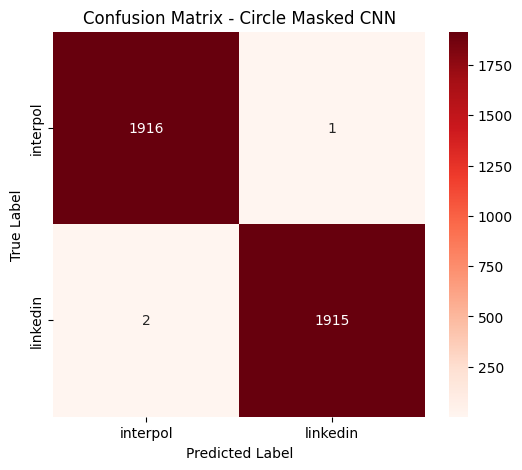

In [ ]:
from sklearn.metrics import accuracy_score, confusion_matrix
import seaborn as sns

test_gen_circ.reset()
y_pred_prob_circ = model_circ.predict(test_gen_circ, verbose=1)
y_pred_circ = (y_pred_prob_circ > 0.5).astype(int).flatten()
y_true_circ = test_gen_circ.classes

acc_circ = accuracy_score(y_true_circ, y_pred_circ)
print(f"\nAccuracy on Circle-Masked Test Set: {acc_circ:.4f}")

cm_circ = confusion_matrix(y_true_circ, y_pred_circ)

plt.figure(figsize=(6, 5))
sns.heatmap(cm_circ, annot=True, fmt='d', cmap='Reds', xticklabels=class_labels_faces, yticklabels=class_labels_faces)
plt.title('Confusion Matrix - Circle Masked CNN')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.show()